# Searching for periodic signals in gappy data

Satellites in low Earth orbit cannot watch a source continuously: every ~96 minutes the Earth gets in the way. When we look for a signal that repeats every few hours (an orbiting binary star, say), those gaps mean **some parts of the source's cycle are observed more often than others**.

A test that assumes every phase was watched equally will mistake that observing pattern for a real signal. This notebook shows the problem, and fixes it with an *exposure-corrected* test built on Astropy:

| Step | Astropy tools |
|---|---|
| Simulate / read photon event files | `astropy.io.fits`, `astropy.table`, `astropy.time`, `astropy.units` |
| Phase coverage of the observing windows | `astropy.stats.fold_intervals`, `cdf_from_intervals`, `histogram_intervals` |
| Modulation tests | `astropy.stats.kuiper`, `rayleightest` |
| Period search | `astropy.timeseries.BinnedTimeSeries`, `LombScargle` |

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import phasecover as pc

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2026)
PERIOD = 5 * u.hour

## 1. A realistic observing pattern

30 hours of observation from a 96-minute orbit, with the target visible ~55% of each orbit.

19 good time intervals, total exposure 16.7 h of 30 h


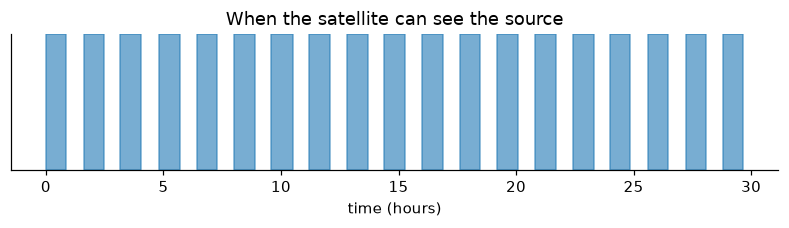

In [2]:
gtis = pc.leo_gtis(30 * u.hour, orbit_period=96 * u.min, visible_fraction=0.55, rng=rng)
print(f"{len(gtis)} good time intervals, total exposure {np.sum(np.diff(gtis)) / 3600:.1f} h of 30 h")

fig, ax = plt.subplots(figsize=(9, 1.6))
for start, stop in gtis / 3600:
    ax.axvspan(start, stop, color="C0", alpha=0.6)
ax.set_yticks([]); ax.set_xlabel("time (hours)"); ax.set_title("When the satellite can see the source")
plt.show()

## 2. A source with no signal still *looks* modulated

We simulate a perfectly **constant** source (2 counts/s) and fold the photons at a trial period of 5 hours.

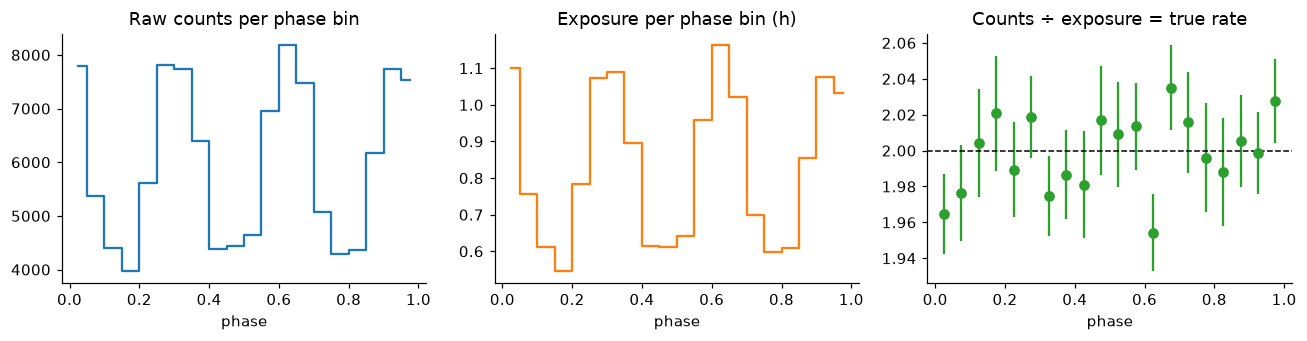

In [3]:
times_const = pc.simulate_events(gtis, rate=2.0, rng=rng)

nbins = 20
phase, rate, rate_err, exposure = pc.folded_profile(times_const, gtis, PERIOD, nbins=nbins)
counts = rate * exposure

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].step(phase, counts, where="mid"); axes[0].set_title("Raw counts per phase bin")
axes[1].step(phase, exposure / 3600, where="mid", color="C1"); axes[1].set_title("Exposure per phase bin (h)")
axes[2].errorbar(phase, rate, rate_err, fmt="o", color="C2"); axes[2].axhline(2.0, ls="--", c="k", lw=1)
axes[2].set_title("Counts ÷ exposure = true rate")
for ax in axes: ax.set_xlabel("phase")
fig.tight_layout(); plt.show()

The raw counts (left) vary strongly with phase, but only because the exposure (middle) does. Dividing them out (right) recovers the constant 2 counts/s. The exposure curve comes from `astropy.stats.fold_intervals`, which folds every observing window onto one cycle.

Now the formal tests:

In [4]:
result = pc.modulation_test(times_const, gtis, PERIOD)
print(result.summary())

Trial period          : 18000 s
Events                : 120326
Naive Kuiper   D, fpp : 0.0462, 5.32e-221
Naive Rayleigh fpp    : 3.13e-09
Corrected Kuiper D,fpp: 0.0030, 0.761


Both naive tests (Kuiper against a uniform distribution, and the Rayleigh test) report an absurdly significant "detection". The corrected Kuiper test compares the photon phases against `cdf_from_intervals(...)`, the distribution *expected* from the real coverage, and correctly finds nothing.

## 3. Is the corrected test trustworthy? A Monte Carlo check

If a test is calibrated, its false-positive probability (fpp) should be roughly uniform between 0 and 1 when there is no signal. Repeat the experiment 200 times:

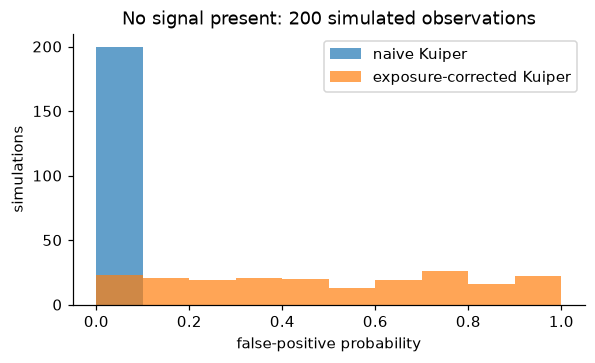

'Detections' at fpp < 0.01 -> naive: 100%, corrected: 0%


In [5]:
naive, corrected = [], []
for seed in range(200):
    r = np.random.default_rng(seed)
    g = pc.leo_gtis(30 * u.hour, rng=r)
    t = pc.simulate_events(g, rate=0.5, rng=r)
    res = pc.modulation_test(t, g, PERIOD)
    naive.append(res.naive_kuiper_fpp); corrected.append(res.corrected_kuiper_fpp)
naive, corrected = np.array(naive), np.array(corrected)

fig, ax = plt.subplots(figsize=(6, 3.2))
bins = np.linspace(0, 1, 11)
ax.hist(np.clip(naive, 0, 1), bins, alpha=0.7, label="naive Kuiper")
ax.hist(corrected, bins, alpha=0.7, label="exposure-corrected Kuiper")
ax.set_xlabel("false-positive probability"); ax.set_ylabel("simulations"); ax.legend()
ax.set_title("No signal present: 200 simulated observations")
plt.show()
print(f"'Detections' at fpp < 0.01 -> naive: {np.mean(naive < 0.01):.0%}, corrected: {np.mean(corrected < 0.01):.0%}")

The naive test claims a detection almost every time. The corrected test's p-values are spread across [0, 1], as they should be for a well-calibrated test. (Kuiper's false-positive formula is approximate, so the spread is not perfectly flat.)

## 4. Detecting a real but weak signal

Now add a genuine 3% sinusoidal modulation at the 5-hour period.

Trial period          : 18000 s
Events                : 119722
Naive Kuiper   D, fpp : 0.0521, 1.22e-279
Naive Rayleigh fpp    : 9.96e-43
Corrected Kuiper D,fpp: 0.0126, 3.5e-15
Significant after exposure correction: True


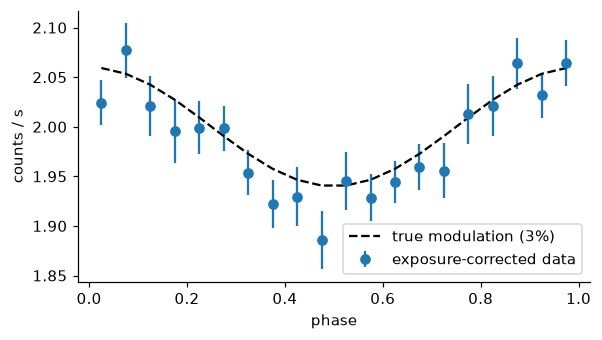

In [6]:
times_mod = pc.simulate_events(gtis, rate=2.0, period=PERIOD, pulsed_fraction=0.03, rng=rng)
result = pc.modulation_test(times_mod, gtis, PERIOD)
print(result.summary())
print("Significant after exposure correction:", result.is_significant())

phase, rate, rate_err, _ = pc.folded_profile(times_mod, gtis, PERIOD, nbins=nbins)
model = 2.0 * (1 + 0.03 * np.cos(2 * np.pi * phase))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(phase, rate, rate_err, fmt="o", label="exposure-corrected data")
ax.plot(phase, model, "k--", label="true modulation (3%)")
ax.set_xlabel("phase"); ax.set_ylabel("counts / s"); ax.legend()
plt.show()

## 5. Finding the period without knowing it

So far we assumed the trial period. With a stronger signal we can also search for it: bin the events into a light curve (`BinnedTimeSeries`, using only bins fully inside a good time interval) and compute a Lomb–Scargle periodogram.

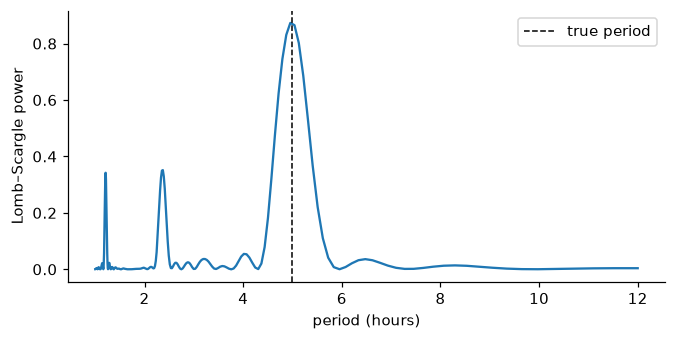

Best period: 4.956 h  (false-alarm probability 1.1e-81)


In [7]:
times_strong = pc.simulate_events(gtis, rate=2.0, period=PERIOD, pulsed_fraction=0.15, rng=rng)
lc = pc.binned_lightcurve(times_strong, gtis, 5 * u.min)
periods, power, best, fap = pc.period_search(lc, 1 * u.hour, 12 * u.hour)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(periods.to(u.hour), power)
ax.axvline(PERIOD.to_value(u.hour), ls="--", c="k", lw=1, label="true period")
ax.set_xlabel("period (hours)"); ax.set_ylabel("Lomb–Scargle power"); ax.legend()
plt.show()
print(f"Best period: {best.to(u.hour):.3f}  (false-alarm probability {fap:.1e})")

The highest peak sits at the true period. The two smaller peaks are **aliases** produced by the gaps themselves: the 96-minute orbit (frequency 1/1.6 h⁻¹) beats against the 5-hour signal (1/5 h⁻¹), creating power at 1/1.6 ± 1/5 h⁻¹, i.e. periods of about **1.21 h** and **2.35 h**. Knowing where these appear avoids mistaking them for new signals.

## 6. Working with real event files

Missions such as NICER and XMM-Newton distribute photons as FITS files with an `EVENTS` table and a `GTI` table, with times in seconds since a reference epoch (`MJDREFI`/`MJDREFF`). `phasecover` reads and writes that layout, so the same analysis runs on archive data:

In [8]:
pc.write_events("example_events.fits", times_mod, gtis, TELESCOP="SIMULATED", OBJECT="TEST-SOURCE")
events = pc.read_events("example_events.fits")
print(events.meta, "| start:", events.start_time.utc.iso, "| exposure:", events.exposure.to(u.ks).round(2))
print(pc.modulation_test(events.times, events.gtis, PERIOD).summary())

{'TELESCOP': 'SIMULATED', 'OBJECT': 'TEST-SOURCE'} | start: 2013-12-31 23:58:52.816 | exposure: 60.23 ks
Trial period          : 18000 s
Events                : 119722
Naive Kuiper   D, fpp : 0.0521, 1.22e-279
Naive Rayleigh fpp    : 9.96e-43
Corrected Kuiper D,fpp: 0.0126, 3.5e-15


The same thing from the command line:

```bash
phasecover simulate obs.fits --pulsed-fraction 0.03 --seed 1
phasecover analyze obs.fits --period 5 --plot profile.png
```

## A note on an upstream bug

`astropy.stats.fold_intervals` (Astropy ≤ 8.0.x) loses one full cycle of coverage for any window that ends exactly on a cycle boundary. A single full cycle gets **zero** exposure, which makes `cdf_from_intervals` fail. I reported and submitted a fix upstream ([astropy/astropy#20671](https://github.com/astropy/astropy/pull/20671)). Until it is released, `phasecover.fold_gtis` detects the faulty behaviour and corrects for it.

In [9]:
from astropy.stats import fold_intervals
print("astropy fold_intervals, one full cycle :", fold_intervals([(0.0, 1.0, 1.0)])[1])
print("phasecover.fold_gtis, one full cycle   :", pc.fold_gtis([[0.0, 3600.0]], 1 * u.hour)[1])

astropy fold_intervals, one full cycle : [0.]
phasecover.fold_gtis, one full cycle   : [1.]
